In [83]:
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [84]:
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [85]:
path = kagglehub.dataset_download(
    "hamdallak/the-iqothnccd-lung-cancer-dataset"
)

print("Path to dataset:", path)

Using Colab cache for faster access to the 'the-iqothnccd-lung-cancer-dataset' dataset.
Path to dataset: /kaggle/input/the-iqothnccd-lung-cancer-dataset


In [86]:
import os

for folder in os.listdir(path):
    folder_path = os.path.join(path, folder)

    if os.path.isdir(folder_path):
        print(f"Folder: {folder}")
        print(f"Path: {folder_path}")
        print(f"Number of files: {len(os.listdir(folder_path))}")

Folder: The IQ-OTHNCCD lung cancer dataset
Path: /kaggle/input/the-iqothnccd-lung-cancer-dataset/The IQ-OTHNCCD lung cancer dataset
Number of files: 4


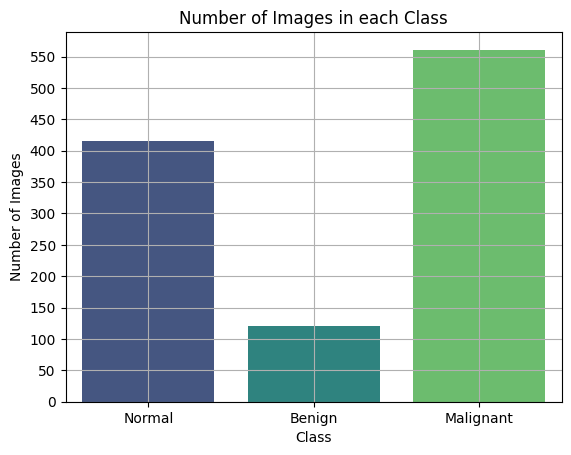


--------------------------------------------------
{'Normal': 416, 'Benign': 120, 'Malignant': 561}


In [ ]:
import numpy as np

def path_finder(base_path):

    targets = {
        "normal cases": "Normal",
        "bengin cases": "Benign",
        "malignant cases": "Malignant"
    }

    paths = {}

    for root, dirs, _ in os.walk(base_path):
        for folder in dirs:
            folder_clean = folder.lower().strip()
            if folder_clean in targets:
                class_name = targets[folder_clean]
                paths[class_name] = os.path.join(root, folder)

    return paths

paths = path_finder(path)

counts = {}

for label, folder_path in paths.items():
    if folder_path is None:
        print(f"Folder not found: {label}")
    else:
        counts[label] = sum(
            f.lower().endswith((".jpg", ".jpeg", ".png"))
            for f in os.listdir(folder_path)
        )

if len(counts) == 3:
    sns.barplot(
        x=list(counts.keys()),
        y=list(counts.values()),
        hue=list(counts.keys()),
        palette="viridis",
        legend=False
    )
    plt.title("Number of Images in each Class")
    plt.xlabel("Class")
    plt.ylabel("Number of Images")
    plt.yticks(np.arange(0, 600, 50))
    plt.grid()
    plt.show()

    print(f"\n{50 * "-"}\n{counts}")

The data distribution for the "Normal" and "Malignant" categories is adequate and relatively balanced.
However, for the "Benign" category, the amount of data is less than ideal, which results in an imbalanced dataset.

One potential solution is to remove this category—a seemingly logical step; however, given that our entire dataset is already small, this is not an ideal approach. Another option is to merge this category with the "Malignant" category; while this would also result in an imbalanced dataset, the degree of imbalance is minor and essentially negligible.

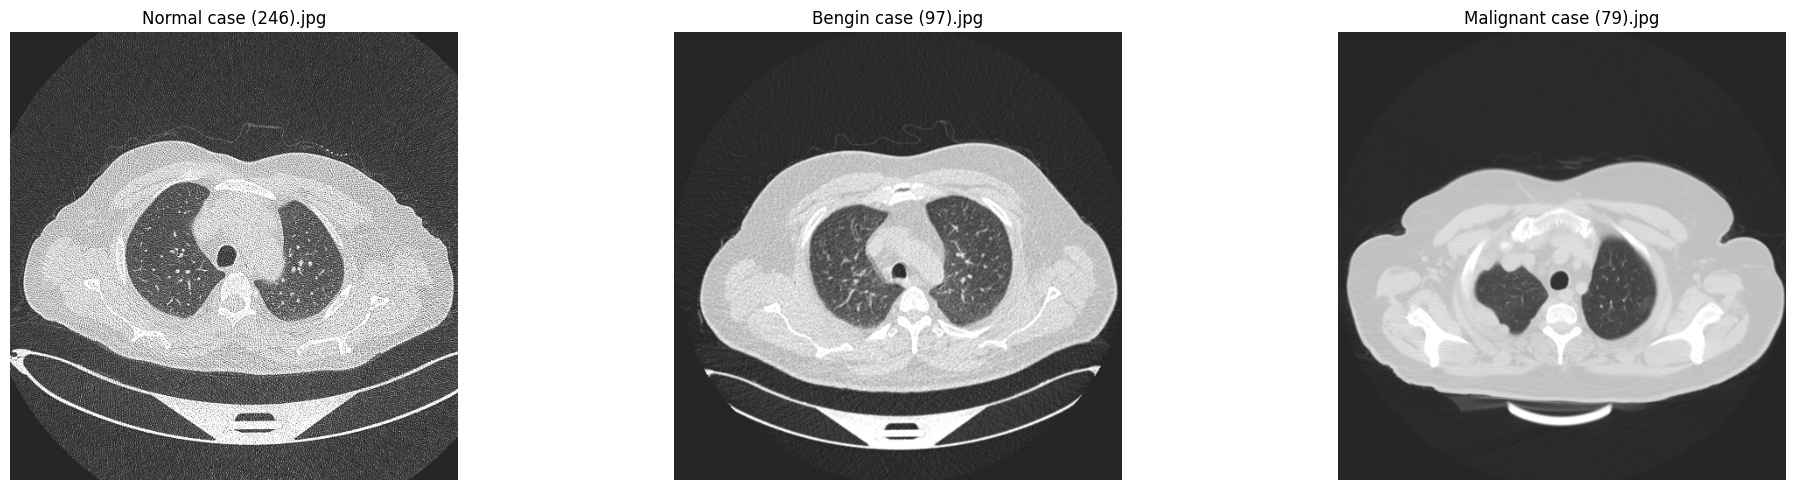

In [95]:
first_path_0 = list(paths.values())[0]
image_files_0 = [f for f in os.listdir(first_path_0) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

first_path_1 = list(paths.values())[1]
image_files_1 = [f for f in os.listdir(first_path_1) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

first_path_2 = list(paths.values())[2]
image_files_2 = [f for f in os.listdir(first_path_2) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

img_path_0 = os.path.join(first_path_0, image_files_0[0])
img_path_1 = os.path.join(first_path_1, image_files_1[0])
img_path_2 = os.path.join(first_path_2, image_files_2[0])

img_0 = cv2.imread(img_path_0)
img_1 = cv2.imread(img_path_1)
img_2 = cv2.imread(img_path_2)

fig, axes = plt.subplots(1, 3, figsize=(21, 5), sharey=True)

img_rgb_0 = cv2.cvtColor(img_0, cv2.COLOR_BGR2RGB)
axes[0].imshow(img_rgb_0)
axes[0].set_title(image_files_0[0])
axes[0].axis('off')

img_rgb_1 = cv2.cvtColor(img_1, cv2.COLOR_BGR2RGB)
axes[1].imshow(img_rgb_1)
axes[1].set_title(image_files_1[0])
axes[1].axis('off')

img_rgb_2 = cv2.cvtColor(img_2, cv2.COLOR_BGR2RGB)
axes[2].imshow(img_rgb_2)
axes[2].set_title(image_files_2[0])
axes[2].axis('off')

plt.tight_layout()
plt.show()

#### The quality of the data varies. This has been investigated and the problem is with the data itself.
#### Their order:
- Normal
- Malignant
- Benign

#### This file served merely as a brief examination of the dataset components.
##### In the main file, these components will be combined, resulting in two scenarios:
1. Normal ---> 0
2. Abnormal = Benign and Malignant ---> 1